# 4. Évaluation du pipeline RAG

**Critère** : **F1 BERTScore > 60 %** entre la réponse de l'assistant et la réponse attendue (`answers.json`), sur les 619 questions de `queries.json`.
**Protocole** : pipeline de production (index construit depuis les 63 PDF, découpage maison), question posée **sans historique**, puis `bert_score.score(..., lang="fr")` (modèle multilingue par défaut de la bibliothèque, **sans rééchelonnage** — c'est le score « brut » usuel). Le score rééchelonné (baseline) est aussi rapporté.

Transparence sur le réglage : le premier diagnostic du prompt (version 1) a été fait sur les résultats des 619 questions ; les corrections de prompt suivantes ont ensuite été mesurées sur un **sous-échantillon aléatoire de 200 questions** (graine 0) ; le choix du découpage et de l'en-tête a été arbitré sur les 619. Le score sur les **419 autres** reste donc le plus proche d'une estimation indépendante, sans l'être totalement.

In [1]:
import os, sys, json, time, warnings
warnings.filterwarnings("ignore")
os.environ["TOKENIZERS_PARALLELISM"] = "false"
sys.path.insert(0, os.path.abspath(".."))
import pandas as pd, numpy as np
pd.set_option("display.max_colwidth", 110, "display.width", 200, "display.max_columns", 30)
import random, matplotlib.pyplot as plt
from rag.config import *
from rag.evaluation import load_eval, run_generation, bertscore, coverage, exact_retrieval, pdf_retrieval, corpus_documents
from rag.pipeline import default_assistant, RagAssistant
from rag.embeddings import LocalEmbeddings
from rag.store import build_store
ev = load_eval()
tuning = set(random.Random(0).sample(list(ev["queries"]), 200))   # sous-échantillon utilisé pour régler prompt/découpage
print(f"{len(ev['queries'])} questions | {len(tuning)} de réglage | {len(ev['queries']) - len(tuning)} hors sous-échantillon de réglage")

619 questions | 200 de réglage | 419 hors sous-échantillon de réglage


## 4.1 Comparaison des configurations de découpage (bout en bout)
Produit par `python -m rag.sweep 900:150:1 900:150:0 1300:200:1` (les 619 questions pour chaque configuration).

In [2]:
sweep = pd.read_csv("../resultats/comparaison_configs.csv"); sweep

,config,chunk_size,overlap,en_tete_produit,n_chunks,f1_bertscore,f1_median,part_introuvable,mots_par_reponse,duree_s
0,chunk900_ov150_hdr1,900,150,True,1384,0.7551,0.7444,0.160,22.4,747
1,chunk900_ov150_hdr0,900,150,False,1384,0.7787,0.7725,0.123,19.3,674
2,chunk1300_ov200_hdr1,1300,200,True,929,0.7541,0.7525,0.165,23.2,895


## 4.2 Évaluation de la configuration retenue
Génération des 619 réponses par le pipeline final (LLM local, ~12 min).

In [3]:
bot = default_assistant()
t = time.time(); res = run_generation(bot, ev); print(f"génération : {time.time() - t:.0f}s")
res["f1"] = bertscore(res.reponse.tolist(), res.reference.tolist())
res["reglage"] = res.uuid.isin(tuning)
res.to_csv("../resultats/resultats_evaluation.csv", index=False)
res.head(5)

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 6066.07it/s]

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 393/393 [00:00<00:00, 5488.90it/s]

génération : 739s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9052.88it/s]


[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,uuid,question,reference,reponse,trouve,sources,f1,reglage
0,6ca4da60-a74c-45cb-b41c-c5fac380b7b9,Quel est l'objectif de gestion du FCP décrit dans le document ?,La recherche d'une performance sur la durée de placement recommandée supérieure à 5 ans par un placement s...,"L'objectif de gestion du FCP est de mettre en œuvre une gestion discrétionnaire pour surperformer, via une...",True,SODIFY.pdf p.1,0.680812,False
1,0be2c984-debb-4c78-96f9-754dce277409,Quels critères sont pris en compte dans les décisions d'investissement du FCP ?,"Les critères financiers et extra-financiers, notamment les critères de responsabilité environnementale, so...","Les décisions d'investissement intègrent à la fois des critères financiers et extra-financiers, notamment ...",True,FR0007050570_DIC_FR_20230630.pdf p.1; FR0011443225_DIC_FR_20230630.pdf p.1; FR0011443233_DIC_FR_20230630.p...,0.880891,True
2,3859c017-ac8e-41bd-971f-d5d5e375b97e,A quoi vise la prise en compte des critères ESG dans la sélection de titres du FCP ?,Evaluer la capacité des entreprises à transformer les enjeux du développement durable en vecteurs de perfo...,Elle vise à évaluer la capacité des entreprises à transformer les enjeux du développement durable en vecte...,True,FR0007050570_DIC_FR_20230630.pdf p.1,0.937257,False
3,8a72a582-d7bf-44ad-84d5-fc3e4b8b8262,Quels sont les scénarios mentionnés pour un investissement utilisant un mandataire approprié ?,"Scénario favorable, scénario intermédiaire, scénario défavorable","Les scénarios mentionnés sont le scénario favorable, le scénario intermédiaire et le scénario défavorable.",True,KIDPRIIPs_375641_89603_FRA_FRA_20230905.pdf p.2; KIDPRIIPs_448123_79630_FRA_FRA_20240101.pdf p.2; KIDPRIIP...,0.822616,False
4,e943d006-d450-4c3c-897a-4ca810a92dde,Quelles sont les dates associées à chaque scénario pour un investissement utilisant un mandataire approprié ?,"Scénario favorable : entre le 31/10/2016 et le 29/10/2021, Scénario intermédiaire : entre le 30/04/2014 et...",Je n'ai pas trouvé cette information dans les documents d'informations clés disponibles.,False,,0.544830,False


In [4]:
def boot_ci(x, n=2000, seed=0):
    rng = np.random.default_rng(seed); x = np.asarray(x)
    m = [rng.choice(x, len(x)).mean() for _ in range(n)]
    return np.percentile(m, [2.5, 97.5])
rows = []
for name, sub in [("TOUTES (619)", res), ("hors sous-échantillon de réglage (419)", res[~res.reglage]), ("sous-échantillon de réglage (200)", res[res.reglage])]:
    lo, hi = boot_ci(sub.f1)
    rows.append({"jeu": name, "F1 BERTScore": round(sub.f1.mean(), 4), "IC95 %": f"[{lo:.3f} ; {hi:.3f}]", "médiane": round(sub.f1.median(), 4)})
score_tab = pd.DataFrame(rows); score_tab

,jeu,F1 BERTScore,IC95 %,médiane
0,TOUTES (619),0.7544,[0.745 ; 0.764],0.7436
1,hors sous-échantillon de réglage (419),0.7579,[0.747 ; 0.770],0.7513
2,sous-échantillon de réglage (200),0.7471,[0.730 ; 0.765],0.7354


In [5]:
f1_all = res.f1.mean(); f1_held = res[~res.reglage].f1.mean()
print(f"F1 BERTScore global : {f1_all:.1%}   |   sur les 419 questions hors sous-échantillon de réglage : {f1_held:.1%}")
print("Seuil de 60 % :", "ATTEINT ✅" if min(f1_all, f1_held) > 0.60 else "NON ATTEINT ❌")

F1 BERTScore global : 75.4%   |   sur les 419 questions hors sous-échantillon de réglage : 75.8%
Seuil de 60 % : ATTEINT ✅


## 4.3 Lire ce score avec esprit critique
BERTScore *non rééchelonné* avec un modèle multilingue est **généreux** : n'importe quelle phrase française de longueur voisine obtient déjà un score élevé. On calcule donc (a) le score rééchelonné (baseline) et (b) le score d'une **réponse constante** qui ne contient aucune information (le message de refus).

In [6]:
from rag.prompts import refus
const = bertscore([refus()] * len(res), res.reference.tolist())
resc = bertscore(res.reponse.tolist(), res.reference.tolist(), rescale=True)
resc_const = bertscore([refus()] * len(res), res.reference.tolist(), rescale=True)
ctrl = pd.DataFrame([
    {"réponses": "pipeline RAG", "F1 brut": np.mean(res.f1), "F1 rééchelonné": np.mean(resc)},
    {"réponses": "réponse constante (message de refus)", "F1 brut": np.mean(const), "F1 rééchelonné": np.mean(resc_const)}]).round(4)
ctrl.to_csv("../resultats/controle_baseline_bertscore.csv", index=False); ctrl

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 51694.94it/s]


[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9243.98it/s]


[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 31136.14it/s]


[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,réponses,F1 brut,F1 rééchelonné
0,pipeline RAG,0.7544,0.3446
1,réponse constante (message de refus),0.6374,0.0323


## 4.4 Où se gagnent et se perdent les points

                           n  part     f1
groupe                                   
refus (« introuvable »)  105  0.17  0.620
réponse donnée           514  0.83  0.782

Mots par réponse : assistant 22.3 | référence 15.2


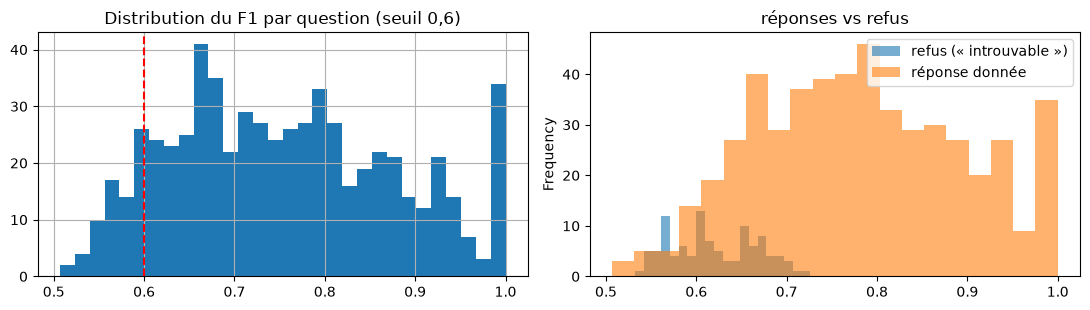

In [7]:
res["n_ref"] = res.reference.str.split().str.len(); res["n_rep"] = res.reponse.fillna("").str.split().str.len()
res["groupe"] = np.where(res.trouve, "réponse donnée", "refus (« introuvable »)")
print(res.groupby("groupe").agg(n=("f1", "size"), part=("f1", lambda s: len(s) / len(res)), f1=("f1", "mean")).round(3).to_string())
print(f"\nMots par réponse : assistant {res.n_rep.mean():.1f} | référence {res.n_ref.mean():.1f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
res.f1.hist(bins=30, ax=ax[0]); ax[0].axvline(0.6, color="r", ls="--"); ax[0].set_title("Distribution du F1 par question (seuil 0,6)")
res.groupby("groupe").f1.plot.hist(bins=20, alpha=.6, ax=ax[1], legend=True); ax[1].set_title("réponses vs refus"); plt.tight_layout(); plt.show()

In [8]:
print("Questions sous 0,60 :", (res.f1 < 0.6).sum(), "/", len(res))
print("\n--- les plus mauvaises réponses données ---")
for _, r in res[res.trouve].nsmallest(8, "f1").iterrows():
    print(f"[{r.f1:.2f}] Q: {r.question[:100]}\n      REF: {r.reference[:90]}\n      REP: {str(r.reponse)[:130]}")

Questions sous 0,60 : 58 / 619

--- les plus mauvaises réponses données ---
[0.51] Q: Quelle est la limite de l'investissement dans les obligations contingentes convertibles (CoCos) par 
      REF: 8%
      REP: La limite d'investissement dans les obligations contingentes convertibles (CoCos) varie selon le produit : 10% maximum de l'actif 
[0.52] Q: Quelles sont les limites de pourcentage maximum de l'actif net pour les obligations de qualité mais 
      REF: 15%
      REP: Les limites de pourcentage maximum de l'actif net pour les obligations de qualité mais non notées varient selon le produit : 10% p
[0.53] Q: Quels sont les coûts totaux si l'investissement est sorti après 5 ans ?
      REF: 134 $
      REP: Les coûts totaux varient selon le produit : 1 454 € (29 HAUSSMANN EQUILIBRE), 1 296 € (29 Haussman Euro Rendement - Part C), 1 349
[0.53] Q: Quelles sont les limites en pourcentage de l'actif net du fonds pour les obligations de qualité mais
      REF: 10%
      REP: Les limites

## 4.5 Qualité du retrieval (index final)

In [9]:
from rag.ingest import build_chunks, list_pdfs
chunks = build_chunks(json.loads(CATALOG_PATH.read_text(encoding="utf-8")))
texts = [d.page_content for d in chunks]
ret = pdf_retrieval(bot.retrieve, ev["queries"], ev["relevant_docs"], ev["corpus"], texts, ks=(1, 3, 5))
print("Index PDF (pipeline final), passage de référence couvert à ≥ 50 % :", {k: round(v, 3) if isinstance(v, float) else v for k, v in ret.items()})
res["couvert"] = [coverage(ev["corpus"][ev["relevant_docs"][u][0]], [d.page_content for d in bot.retrieve(q)]) >= 0.5 for u, q in zip(res.uuid, res.question)]
print("\nRefus × passage de référence présent dans les extraits fournis au LLM :")
pd.crosstab(res.trouve.map({True: "réponse", False: "refus"}), res.couvert.map({True: "passage dans les extraits", False: "passage absent (retrieval)"}), margins=True)

Index PDF (pipeline final), passage de référence couvert à ≥ 50 % : {'hit@1': 0.412, 'hit@3': 0.575, 'hit@5': 0.638, 'n_evaluables': 577, 'n_total': 619}



Refus × passage de référence présent dans les extraits fournis au LLM :


couvert,passage absent (retrieval),passage dans les extraits,All
trouve,,,
refus,58,47,105
réponse,193,321,514
All,251,368,619


Les refus avec « passage absent » sont des **échecs de retrieval** (le LLM refuse plutôt qu'inventer — comportement voulu) ; ceux avec « passage présent » sont de la sur-prudence résiduelle du LLM.

## 4.6 Variante : corpus fermé du dataset
Même pipeline mais l'index contient **uniquement les 250 chunks de `corpus.json`** (protocole « fermé » du dataset, où le passage pertinent est forcément indexé tel quel).

In [10]:
docs250, ids250 = corpus_documents(ev["corpus"])
emb = bot.store._embedding_function
st250 = build_store("eval_corpus250", docs250, emb, ids=[f"c{i}" for i in range(len(docs250))])
bot250 = RagAssistant(st250, k=TOP_K, reranker=bot.reranker, fetch_k=FETCH_K)
t = time.time(); res250 = run_generation(bot250, ev); print(f"génération : {time.time() - t:.0f}s")
res250["f1"] = bertscore(res250.reponse.tolist(), res250.reference.tolist())
res250.to_csv("../resultats/resultats_evaluation_corpus250.csv", index=False)
print(f"F1 BERTScore (corpus fermé, 250 chunks) : {res250.f1.mean():.1%} | refus : {(~res250.trouve).mean():.1%}")
print("Retrieval exact (index 250 chunks, avec reranker) :", {k: round(v, 3) for k, v in exact_retrieval(type("S", (), {"similarity_search": lambda s, q, k: bot250.retrieve(q)[:k]})(), ids250, ev["queries"], ev["relevant_docs"], ks=(1, 3, 5)).items()})

génération : 615s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 32399.13it/s]


[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


F1 BERTScore (corpus fermé, 250 chunks) : 79.3% | refus : 9.2%


Retrieval exact (index 250 chunks, avec reranker) : {'hit@1': 0.378, 'hit@3': 0.599, 'hit@5': 0.724, 'mrr': 0.503}


## 4.7 Synthèse

In [11]:
summary = {
    "f1_bertscore_619_questions": round(float(res.f1.mean()), 4),
    "f1_bertscore_419_questions_hors_reglage": round(float(res[~res.reglage].f1.mean()), 4),
    "f1_bertscore_corpus_ferme_250_chunks": round(float(res250.f1.mean()), 4),
    "f1_rescale_619": round(float(np.mean(resc)), 4),
    "f1_reponse_constante_refus": round(float(np.mean(const)), 4),
    "part_refus": round(float((~res.trouve).mean()), 3),
    "seuil_projet": 0.60,
    "modele_llm": bot.llm.model_name, "embedding": EMBED_MODEL, "reranker": RERANK_MODEL,
    "chunk_size": CHUNK_SIZE, "chunk_overlap": CHUNK_OVERLAP, "en_tete_produit": WITH_HEADER, "top_k": TOP_K,
}
json.dump(summary, open("../resultats/synthese_evaluation.json", "w"), ensure_ascii=False, indent=1); summary

{'f1_bertscore_619_questions': 0.7544,
 'f1_bertscore_419_questions_hors_reglage': 0.7579,
 'f1_bertscore_corpus_ferme_250_chunks': 0.7927,
 'f1_rescale_619': 0.3446,
 'f1_reponse_constante_refus': 0.6374,
 'part_refus': 0.17,
 'seuil_projet': 0.6,
 'modele_llm': 'unsloth/Qwen3.8-27B-NVFP4',
 'embedding': 'BAAI/bge-m3',
 'reranker': 'BAAI/bge-reranker-v2-m3',
 'chunk_size': 900,
 'chunk_overlap': 150,
 'en_tete_produit': True,
 'top_k': 5}